# MVP — Análise de Dados e Boas Práticas
**Sprint: Análise de Dados e Boas Práticas — PUC-Rio**

**Projeto:** Análise exploratória e pré-processamento de sensores de poços submarinos: estudo da obstrução por hidrato no 3W Dataset (evento 8)  
**Aluno:** Leonardo Cesar Barduzzi  
**Matrícula:** 4052026001555  
**Base de dados:** 3W Dataset (Petrobras / CENPES / UFRJ), versão 2.0.0  
**Versão entregue:** [Preencher]  
**Link do Google Colab:** [Preencher]

# 1. Problema e hipóteses de trabalho

## 1.1 Contexto e objetivo

Em linhas de produção submarinas em águas profundas, o contato entre água e gás natural sob alta pressão e baixa temperatura pode formar hidratos — estruturas sólidas semelhantes a gelo que aderem às paredes internas dos dutos. Esse acúmulo restringe a passagem do fluido e pode causar o bloqueio total da linha, gerando prejuízos financeiros e riscos operacionais significativos. A detecção precoce do hidrato ajuda a equipe de operação a agir a tempo (ajustando a injeção de inibidores como MEG ou alinhando despressurizações), evitando paradas de emergência.

O objetivo deste trabalho é **analisar as leituras dos sensores submarinos nos períodos em que especialistas rotularam a presença de hidrato na linha de produção**, verificando quais variáveis físicas realmente indicam o problema e em quais momentos operacionais ele costuma acontecer.

**Unidade de observação e recorte.** Cada linha da base corresponde à leitura dos sensores em um instante de 1 segundo (amostragem em 1 Hz). Os dados estão organizados em arquivos chamados **instâncias**, onde cada arquivo registra a evolução temporal de um poço específico durante um episódio do evento 8 (hidrato em linha de produção), dividido em blocos contínuos de operação normal, transição e hidrato estacionário. O recorte deste trabalho utiliza **14 instâncias reais, cobrindo 9 poços distintos e 4.809.035 leituras** (Seção 3.2). As comparações são feitas poço a poço para respeitar as particularidades de cada instalação; análises conjuntas são usadas apenas para avaliar a consistência geral dos dados.

**Objetivo analítico descritivo.** O trabalho tem escopo estritamente descritivo, sem modelagem preditiva ou machine learning. Essa decisão decorre de três características da própria base:
1. Em cada instância real, as classes aparecem sempre em um único bloco contínuo na mesma ordem (normal $\rightarrow$ transição $\rightarrow$ hidrato); um modelo supervisionado tenderia a aprender a sequência do arquivo em vez da física do fenômeno;
2. Para evitar esse vazamento temporal, a divisão honesta deveria ser feita por poço, mas a base conta com apenas 9 poços reais — uma amostra pequena demais para validação confiável;
3. O hidrato é uma ocorrência rara, presente em apenas 2,93% do volume total de dados analisado.

Dessa forma, não fazemos divisão entre treino e teste, e nenhum parâmetro (como médias para imputação ou escalas de normalização) é aprendido em uma parte dos dados para aplicar em outra. O pré-processamento aplica regras determinísticas e fundamentadas no domínio diretamente sobre a base (Seção 5).

**Sensores e siglas principais:**
- `PDG`: sensor de pressão e temperatura no fundo do poço (*downhole*);
- `TPT`: sensor de pressão e temperatura na árvore de natal molhada (no leito marinho);
- `CKP`: válvula *choke* de produção, que controla o fluxo (medido a montante, `MON`, e a jusante, `JUS`);
- `state`: estado operacional do poço (produzindo em fluxo aberto, fechado, em lavagem/circulação ou reiniciando).

## 1.2 Perguntas e hipóteses de trabalho

Definimos duas perguntas centrais para guiar a análise, além de registrar uma restrição importante de instrumentação:

**Hipótese 1 ($H_1$) — A temperatura sinaliza o hidrato de forma mais clara que a pressão?**
- *Ideia central:* Como a formação de hidrato depende de temperaturas baixas, a temperatura medida na árvore submarina (`T-TPT`) deve cair de maneira mais nítida e consistente do que as pressões (`P-TPT` e `P-MON-CKP`) durante a obstrução.
- *Variáveis:* `T-TPT` e `T-MON-CKP` (temperaturas), comparadas com `P-TPT` e `P-MON-CKP` (pressões).
- *Como testar:* Comparar, dentro de cada poço, a distribuição dos valores no bloco de operação normal (`class = 0`) com o bloco de hidrato estacionário (`class = 8`).
- *O que refutaria a hipótese:* Temperatura praticamente estável ou com separação menor do que a observada nas curvas de pressão.
- *Limitações:* O sensor da árvore sofre influência direta da temperatura do fundo do mar; 5 das 14 instâncias não medem essa variável; e, como os rótulos foram atribuídos sobre esses mesmos dados, a análise mostra associação física, não prova causalidade.

**Hipótese 2 ($H_2$) — O hidrato aparece com o poço produzindo ou durante manobras operacionais?**
- *Ideia central:* O hidrato estacionário tende a se manifestar principalmente quando o poço está em manobras (parada, lavagem de linha ou reinício), e não durante o regime estável de produção contínua.
- *Variáveis:* `class` (classe do evento) e `state` (estado de operação do poço).
- *Como testar:* Cruzar a quantidade de leituras com hidrato (`class = 8`) com os diferentes estados operacionais (`state = 0` para produção aberta vs. estados de manobra).
- *O que refutaria a hipótese:* Encontrar a maior parte das leituras de hidrato durante a produção contínua (*Open*).
- *Limitações:* As manobras de lavagem ou reinício são procedimentos ativados pela equipe de operação justamente para combater a suspeita de obstrução; portanto, a associação reflete o momento de intervenção operacional, não que a manobra tenha sido a causa inicial do hidrato.

**Ponto extra ($H_3$) — Avaliação da perda de carga ($\Delta P$):**
- Seria natural esperar que uma obstrução gerasse aumento na perda de carga entre a árvore e a plataforma ($\Delta P = \text{P-TPT} - \text{P-MON-CKP}$). No entanto, a base não registra a vazão de produção do poço (os atributos `QGL` e `QBS` medem gás de elevação e injeção de serviço). Sem saber a vazão real de fluido, é impossível separar uma queda de pressão por obstrução de uma simples redução na produção do poço. Registramos isso como uma limitação dos dados, e não como uma hipótese testada.

**Recorte utilizado:** Analisamos as 14 instâncias reais de poços (`WELL-*`) do evento 8. Para testar $H_1$, usamos os poços que contam com medições válidas de temperatura; para $H_2$, utilizamos todas as 14 instâncias.

# 2. Fonte dos dados e significado das variáveis

## 2.1 Origem dos dados e como são carregados

| Informação | Detalhe |
|---|---|
| **Origem** | Petrobras / CENPES e UFRJ — **3W Dataset** |
| **Repositório** | <https://github.com/petrobras/3W> |
| **Versão utilizada** | **2.0.0** (lançada em 25/07/2024), fixada no commit `cfb6666659e7a36c352f4206fabbab320f5939c9` |
| **Forma de acesso** | Download via HTTPS direto dos arquivos brutos (*raw storage*), sem necessidade de login ou senhas |
| **Período dos dados** | Séries temporais registradas entre 30/08/2011 e 26/09/2023 |
| **Licença de uso** | Dados públicos sob **Creative Commons Attribution 4.0 (CC BY 4.0)** (atribuição na Seção 8) |
| **Recorte analítico** | Pasta `dataset/8` (hidrato em linha de produção), mantendo apenas as instâncias de poços reais (`WELL-*`) |
| **Critério de escolha** | O evento 8 é o que reúne mais poços reais com a patologia; instâncias simuladas ou desenhadas à mão foram descartadas para focar em dados de campo |

Os 14 arquivos do recorte estão identificados pelo nome e tamanho em bytes no manifesto (§3.2). A função de carga verifica se o arquivo já está baixado no computador com o tamanho exato; se não estiver, faz o download diretamente do repositório da Petrobras:

`https://raw.githubusercontent.com/petrobras/3W/cfb6666659e7a36c352f4206fabbab320f5939c9/dataset/8`

Esse procedimento garante que qualquer pessoa execute exatamente a mesma versão dos dados, sem depender de credenciais privadas. Os arquivos `.parquet` ficam salvos na pasta local `data/3w/8/`, que fica fora do controle de versão do Git para manter o repositório leve.

## 2.2 Dicionário das variáveis

A base reúne 29 variáveis nas 14 instâncias: 27 medições numéricas contínuas (`float64`) e duas colunas inteiras (`Int16`) que identificam o evento (`class`) e o estado do poço (`state`). O índice de tempo (`timestamp`) é do tipo data/hora, com leituras a cada 1 segundo.

| Variável | Significado | Tipo | Unidade / Valores | Situação e dados ausentes |
|---|---|---|---|---|
| `timestamp` | Horário da medição (índice temporal) | datetime | 1 s | Completo e em ordem cronológica estrita |
| `ABER-CKGL` | Abertura da *choke* de gas lift | float | % | 93,58% ausente |
| `ABER-CKP` | Abertura da *choke* de produção | float | % | Trava em `-99,99` no poço WELL-00030 inteiro (código de falha) |
| `ESTADO-DHSV` | Válvula de segurança de fundo | float | 0 / 0,5 / 1 | 52,20% ausente |
| `ESTADO-M1` | Válvula mestra de produção | float | 0 / 0,5 / 1 | 2,66% ausente |
| `ESTADO-M2` | Válvula mestra do anular | float | 0 / 0,5 / 1 | 5,16% ausente |
| `ESTADO-PXO` | Válvula de cruzamento do *pig* | float | 0 / 0,5 / 1 | 7,55% ausente |
| `ESTADO-SDV-GL` | Válvula de corte do gas lift | float | 0 / 0,5 / 1 | 7,57% ausente |
| `ESTADO-SDV-P` | Válvula de corte da produção | float | 0 / 0,5 / 1 | 7,57% ausente |
| `ESTADO-W1` | Válvula lateral de produção | float | 0 / 0,5 / 1 | 0,01% ausente |
| `ESTADO-W2` | Válvula lateral do anular | float | 0 / 0,5 / 1 | 5,10% ausente |
| `ESTADO-XO` | Válvula de cruzamento | float | 0 / 0,5 / 1 | 0,01% ausente |
| `P-ANULAR` | Pressão no espaço anular | float | Pa | 44,89% ausente; com registros negativos irreais |
| `P-JUS-BS` | Pressão a jusante da bomba de serviço | float | Pa | **100% ausente** (não instalado) |
| `P-JUS-CKGL` | Pressão a jusante da *choke* de gas lift | float | Pa | 15,03% ausente |
| `P-JUS-CKP` | Pressão a jusante da *choke* de produção | float | Pa | `-9.999.000` em toda a WELL-00030 (código de falha) |
| `P-MON-CKGL` | Pressão a montante da *choke* de gas lift | float | Pa | 93,58% ausente |
| `P-MON-CKP` | Pressão a montante da *choke* de produção | float | Pa | 0,02% ausente |
| `P-MON-SDV-P` | Pressão a montante da SDV de produção | float | Pa | **100% ausente** (não instalado) |
| `P-PDG` | Pressão no fundo do poço (PDG) | float | Pa | 21,72% ausente; valores absurdos ($> 10^{12}$) em duas instâncias |
| `PT-P` | Pressão na árvore após a PWV | float | Pa | **100% ausente** (não instalado) |
| `P-TPT` | Pressão na árvore submarina (TPT) | float | Pa | 26,97% ausente; travada em `-8.629.852` na WELL-00031 |
| `QBS` | Vazão da bomba de serviço | float | m³/s | **100% ausente** (não instalado) |
| `QGL` | Vazão de injeção de gas lift | float | m³/s | 0,04% ausente |
| `T-JUS-CKP` | Temperatura a jusante da *choke* de produção | float | °C | **100% ausente** (não instalado) |
| `T-MON-CKP` | Temperatura a montante da *choke* de produção | float | °C | Código `-99,99` no poço WELL-00030 inteiro |
| `T-PDG` | Temperatura de fundo de poço (PDG) | float | °C | 21,72% ausente; leituras na ordem de $-10^{20}$ em duas instâncias |
| `T-TPT` | Temperatura na árvore submarina (TPT) | float | °C | 41,27% ausente; travada em approx -25$ °C em duas instâncias |
| `class` | Classe operacional | Int16 | 0 / 108 / 8 | Ausente nas primeiras 3.600 linhas de cada arquivo (1ª hora) |
| `state` | Estado operacional do poço | Int16 | 0 a 8 | Ausente nas mesmas primeiras 3.600 linhas de cada arquivo |

**Significado dos códigos de classe (`class`):**
- `0`: Operação normal;
- `108`: Período de transição para o hidrato ($8 + 100$, padrão adotado na base 3W);
- `8`: Hidrato estacionário (obstrução consolidada na linha de produção);
- `NaN`: Primeira hora de cada gravação (3.600 segundos), deixada sem rótulo para acomodar a estabilização inicial.

**Significado dos códigos de estado (`state`):**
- `0` *Open* (produzindo normalmente em fluxo aberto);
- `1` *Shut-in* (poço fechado);
- `2` *Flushing Diesel* (lavagem de linha com diesel);
- `3` *Flushing Gas* (circulação de gás);
- `4` *Bullheading* (injeção forçada de fluido sob pressão);
- `5` *Closed With Diesel* (fechado com diesel);
- `6` *Closed With Gas* (fechado com gás);
- `7` *Restart* (procedimento de reabertura e reinício);
- `8` *Depressurization* (despressurização para dissolver hidrato).

Os estados de 2 a 8 são procedimentos de contingência descritos pela própria documentação da base, isto é, ações que os operadores executam para tentar resolver problemas de escoamento. O nome do arquivo identifica o poço e o início do registro (ex.: `WELL-00019_20120601`). Os dados omissos aparecem tanto como `NaN` comum quanto como números sentinela de sensor desligado, tratados na Decisão D3 (§5.4).

# 3. Ambiente de execução e carga dos dados

## 3.1 Ambiente de execução e dependências

O notebook pode ser executado diretamente no **Google Colab** (Python 3.11+) ou em um ambiente local com Jupyter. No Colab, as bibliotecas utilizadas já vêm instaladas; em ambiente local, basta rodar `pip install -r requirements.txt`. As versões ativas no ambiente são listadas abaixo para conferência e auditoria.

Embora o trabalho seja descritivo e não utilize algoritmos probabilísticos, fixamos a semente aleatória (`seed = 42`) para garantir que qualquer rotina de amostragem gráfica gere sempre as mesmas saídas.

## 3.2 Como os dados são organizados e carregados

- **Base:** 3W Dataset, versão **2.0.0** (Petrobras / CENPES e UFRJ).
- **Repositório oficial:** <https://github.com/petrobras/3W>, versão fixada no commit `cfb6666`.
- **Condições de uso:** arquivos sob licença **CC BY 4.0**, com atribuição documentada na Seção 8.
- **Recorte analisado:** as **14 instâncias reais** (`WELL-*`) da pasta `dataset/8` (hidrato na linha de produção).

Os arquivos de dados não são versionados no Git para não sobrecarregar o repositório. Eles são baixados diretamente via HTTPS dos servidores do projeto 3W e armazenados na pasta local `data/3w/8/`. A lista abaixo define o nome e o tamanho de cada arquivo; a rotina de carga só aceita arquivos que correspondam exatamente ao tamanho esperado, evitando dados corrompidos ou versões desatualizadas.

A carga é idempotente: se o arquivo já existir com o tamanho correto, ele é lido diretamente do disco. A versão original dos dados é preservada intocada no dicionário `instancias` e não sofre nenhuma alteração ao longo do notebook. Todas as transformações de pré-processamento (Seção 5) são feitas em cópias dedicadas.

In [1]:
import sys
from importlib.metadata import version

print("Python:", sys.version.split()[0])
for pacote in ("pandas", "numpy", "pyarrow", "matplotlib", "seaborn"):
    print(f"{pacote}: {version(pacote)}")


Python: 3.11.9
pandas: 2.3.2
numpy: 2.3.3
pyarrow: 26.0.1
matplotlib: 3.10.9
seaborn: 0.13.2


In [2]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from IPython.display import display

SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)

# Versão fixada da base (commit do repositório oficial do 3W Dataset).
COMMIT_3W = "cfb6666659e7a36c352f4206fabbab320f5939c9"
URL_BASE = f"https://raw.githubusercontent.com/petrobras/3W/{COMMIT_3W}/dataset/8"
CACHE = Path("data") / "3w" / "8"

# As 14 instâncias reais (WELL-*) do evento 8: nome do arquivo e tamanho em bytes.
MANIFESTO = (
    ("WELL-00019_20120601165020.parquet", 5767996),
    ("WELL-00019_20141117190526.parquet", 4357694),
    ("WELL-00019_20150614025713.parquet", 4029250),
    ("WELL-00019_20210617032654.parquet", 2770721),
    ("WELL-00025_20200629194141.parquet", 15511544),
    ("WELL-00026_20160601130000.parquet", 5208057),
    ("WELL-00026_20170207230000.parquet", 14397696),
    ("WELL-00026_20170608230000.parquet", 11874943),
    ("WELL-00027_20230918170106.parquet", 6323563),
    ("WELL-00028_20210617053128.parquet", 3461670),
    ("WELL-00029_20201020231724.parquet", 2593859),
    ("WELL-00030_20141108012623.parquet", 3145442),
    ("WELL-00031_20140403170404.parquet", 4317854),
    ("WELL-00032_20110830235321.parquet", 3337002),
)


In [3]:
def baixar_instancias(manifesto, destino, url_base, timeout=120):
    """Garante no cache cada arquivo do manifesto, conferindo o tamanho em bytes.

    Devolve um registro com a situação de cada arquivo: 'cache' quando já estava
    completo e 'baixado' quando foi obtido nesta execução.
    """
    destino.mkdir(parents=True, exist_ok=True)
    registro = []
    for nome, tamanho in manifesto:
        arquivo = destino / nome
        if arquivo.exists() and arquivo.stat().st_size == tamanho:
            situacao = "cache"
        else:
            resposta = requests.get(f"{url_base}/{nome}", timeout=timeout)
            resposta.raise_for_status()
            if len(resposta.content) != tamanho:
                raise ValueError(
                    f"{nome}: recebidos {len(resposta.content)} bytes, esperados {tamanho}"
                )
            arquivo.write_bytes(resposta.content)
            situacao = "baixado"
        registro.append({"instancia": nome, "MB": tamanho / 1e6, "situacao": situacao})
    return pd.DataFrame(registro)


carga = baixar_instancias(MANIFESTO, CACHE, URL_BASE)
display(carga.groupby("situacao")["MB"].agg(arquivos="count", total_MB="sum").round(1))


,arquivos,total_MB
situacao,,
cache,14,87.1


In [4]:
def nome_do_poco(instancia):
    """Nome do poço a partir do arquivo: 'WELL-00019_2012...' -> 'WELL-00019'."""
    return instancia.split("_")[0]


def carregar_instancias(diretorio, manifesto):
    """Lê um DataFrame por instância, preservando o índice `timestamp` do arquivo."""
    return {nome: pd.read_parquet(diretorio / nome) for nome, _ in manifesto}


instancias = carregar_instancias(CACHE, MANIFESTO)
total_linhas = sum(len(df) for df in instancias.values())
pocos = {nome_do_poco(nome) for nome in instancias}
print(f"{len(instancias)} instâncias | {total_linhas:,} linhas | {len(pocos)} poços distintos")


14 instâncias | 4,809,035 linhas | 9 poços distintos


# 4. Análise exploratória dos dados

## 4.1 Dimensões, tipos de dados e diagnóstico de qualidade

Com 29 colunas distribuídas em 14 arquivos, começamos com um diagnóstico em tabelas: verificamos o volume de dados, os tipos primitivos, a quantidade de ausências, a integridade da contagem de tempo e a sequência de classes registradas em cada arquivo. Os gráficos desta análise estão na Seção 4.3, onde a escolha de cada visualização é explicada com base na pergunta correspondente.

In [5]:
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)


def resumo_dimensoes(instancias):
    """Uma linha por instância: poço, período coberto, linhas, colunas e completude."""
    linhas = []
    for nome, df in instancias.items():
        linhas.append({
            "instancia": nome,
            "poco": nome_do_poco(nome),
            "inicio": df.index.min(),
            "fim": df.index.max(),
            "linhas": len(df),
            "colunas": df.shape[1],
            "ausentes_pct": round(100 * float(df.isna().to_numpy().mean()), 2),
        })
    return pd.DataFrame(linhas).sort_values(["poco", "inicio"]).reset_index(drop=True)


dimensoes = resumo_dimensoes(instancias)
display(dimensoes)

primeira = dimensoes.loc[0, "instancia"]
mesmos_tipos = all(df.dtypes.equals(instancias[primeira].dtypes) for df in instancias.values())
print(f"mesmos tipos nas {len(instancias)} instâncias: {mesmos_tipos}")
display(instancias[primeira].dtypes.rename("tipo").to_frame().T)
display(instancias[primeira].head(3))


,instancia,poco,inicio,fim,linhas,colunas,ausentes_pct
0,WELL-00019_20120601165020.parquet,WELL-00019,2012-06-01 16:50:20,2012-06-04 12:22:36,243137,29,31.14
1,WELL-00019_20141117190526.parquet,WELL-00019,2014-11-17 19:05:26,2014-11-21 10:28:49,314604,29,31.11
2,WELL-00019_20150614025713.parquet,WELL-00019,2015-06-14 02:57:13,2015-06-16 01:30:31,167599,29,31.18
3,WELL-00019_20210617032654.parquet,WELL-00019,2021-06-17 03:26:54,2021-06-20 02:13:37,254804,29,31.15
4,WELL-00025_20200629194141.parquet,WELL-00025,2020-06-29 19:41:41,2020-07-08 04:18:12,722192,29,30.65
5,WELL-00026_20160601130000.parquet,WELL-00026,2016-06-01 13:00:00,2016-06-03 17:00:00,187201,29,31.17
6,WELL-00026_20170207230000.parquet,WELL-00026,2017-02-07 23:00:00,2017-02-14 17:50:00,586201,29,31.08
7,WELL-00026_20170608230000.parquet,WELL-00026,2017-06-08 23:00:00,2017-06-15 00:00:00,522001,29,31.08
8,WELL-00027_20230918170106.parquet,WELL-00027,2023-09-18 17:01:06,2023-09-26 14:01:25,680420,29,44.86
9,WELL-00028_20210617053128.parquet,WELL-00028,2021-06-17 05:31:28,2021-06-20 23:54:26,325379,29,34.62


mesmos tipos nas 14 instâncias: True


,ABER-CKGL,ABER-CKP,ESTADO-DHSV,ESTADO-M1,ESTADO-M2,ESTADO-PXO,ESTADO-SDV-GL,ESTADO-SDV-P,ESTADO-W1,ESTADO-W2,ESTADO-XO,P-ANULAR,P-JUS-BS,P-JUS-CKGL,P-JUS-CKP,P-MON-CKGL,P-MON-CKP,P-MON-SDV-P,P-PDG,PT-P,P-TPT,QBS,QGL,T-JUS-CKP,T-MON-CKP,T-PDG,T-TPT,class,state
tipo,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,Int16,Int16


,ABER-CKGL,ABER-CKP,ESTADO-DHSV,ESTADO-M1,ESTADO-M2,ESTADO-PXO,ESTADO-SDV-GL,ESTADO-SDV-P,ESTADO-W1,ESTADO-W2,ESTADO-XO,P-ANULAR,P-JUS-BS,P-JUS-CKGL,P-JUS-CKP,P-MON-CKGL,P-MON-CKP,P-MON-SDV-P,P-PDG,PT-P,P-TPT,QBS,QGL,T-JUS-CKP,T-MON-CKP,T-PDG,T-TPT,class,state
timestamp,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2012-06-01 16:50:20,NaN,30.0,NaN,1.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,NaN,NaN,15885410.0,1450061.0,NaN,3537821.0,NaN,13563240.0,NaN,7573838.0,NaN,2.195565,NaN,14.12321,70.11425,47.21301,<NA>,<NA>
2012-06-01 16:50:21,NaN,30.0,NaN,1.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,NaN,NaN,15885410.0,1449747.0,NaN,3537166.0,NaN,13563190.0,NaN,7574023.0,NaN,2.195660,NaN,14.12321,70.11422,47.21461,<NA>,<NA>
2012-06-01 16:50:22,NaN,30.0,NaN,1.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,NaN,NaN,15885410.0,1449433.0,NaN,3536511.0,NaN,13563130.0,NaN,7574207.0,NaN,2.195755,NaN,14.12321,70.11420,47.21621,<NA>,<NA>


In [6]:
def resumo_ausencias(instancias):
    """Ausências por coluna e matriz instância x coluna das colunas sem medição.

    Uma única passada por instância alimenta as duas visões.
    """
    por_coluna = {}
    sem_medicao = {}
    for nome, df in instancias.items():
        faltando = df.isna().sum()
        por_coluna[nome] = faltando
        sem_medicao[nome] = faltando.eq(len(df))
    total = pd.concat(por_coluna, axis=1).sum(axis=1)
    n = sum(len(df) for df in instancias.values())
    tabela = pd.DataFrame({
        "ausentes": total,
        "ausentes_pct": (100 * total / n).round(2),
    }).sort_values("ausentes", ascending=False)
    return tabela, pd.DataFrame(sem_medicao).T


ausencias, sem_medicao = resumo_ausencias(instancias)
print(f"colunas sem nenhuma ausência: {(ausencias['ausentes'] == 0).sum()} de {len(ausencias)}")
display(ausencias[ausencias["ausentes"] > 0])

vazias = sem_medicao.loc[:, sem_medicao.any()]
print(f"colunas sem nenhuma medição em alguma instância ({len(vazias.columns)}):")
display(vazias.astype(int).T)


colunas sem nenhuma ausência: 0 de 29


,ausentes,ausentes_pct
P-JUS-BS,4809035,100.00
QBS,4809035,100.00
T-JUS-CKP,4809035,100.00
P-MON-SDV-P,4809035,100.00
PT-P,4809035,100.00
ABER-CKGL,4500310,93.58
P-MON-CKGL,4500309,93.58
ESTADO-DHSV,2510112,52.20
P-ANULAR,2158891,44.89
T-TPT,1984668,41.27


colunas sem nenhuma medição em alguma instância (19):


,WELL-00019_20120601165020.parquet,WELL-00019_20141117190526.parquet,WELL-00019_20150614025713.parquet,WELL-00019_20210617032654.parquet,WELL-00025_20200629194141.parquet,WELL-00026_20160601130000.parquet,WELL-00026_20170207230000.parquet,WELL-00026_20170608230000.parquet,WELL-00027_20230918170106.parquet,WELL-00028_20210617053128.parquet,WELL-00029_20201020231724.parquet,WELL-00030_20141108012623.parquet,WELL-00031_20140403170404.parquet,WELL-00032_20110830235321.parquet
ABER-CKGL,1,1,1,1,1,1,1,1,1,1,0,0,1,1
ABER-CKP,0,0,0,0,0,0,0,0,1,0,1,0,0,0
ESTADO-DHSV,1,1,1,1,0,0,0,0,1,1,0,1,1,0
ESTADO-PXO,0,0,0,0,0,0,0,0,0,0,0,0,1,0
ESTADO-SDV-GL,0,0,0,0,0,0,0,0,0,0,0,0,1,0
ESTADO-SDV-P,0,0,0,0,0,0,0,0,0,0,0,0,1,0
P-ANULAR,1,1,1,1,0,0,0,0,1,0,0,0,1,1
P-JUS-BS,1,1,1,1,1,1,1,1,1,1,1,1,1,1
P-JUS-CKGL,0,0,0,0,1,0,0,0,0,0,0,0,0,0
P-JUS-CKP,0,0,0,0,0,0,0,0,1,1,0,0,1,1


In [7]:
def resumo_integridade(instancias, passo_esperado="1s"):
    """Duplicidades e regularidade temporal de cada instância."""
    passo = pd.Timedelta(passo_esperado)
    linhas = []
    for nome, df in instancias.items():
        intervalos = df.index.to_series().diff().dropna()
        linhas.append({
            "instancia": nome,
            "linhas": len(df),
            "duracao_h": round((df.index.max() - df.index.min()).total_seconds() / 3600, 2),
            "passo_modal": intervalos.mode().iat[0] if len(intervalos) else pd.NaT,
            "passos_fora_do_padrao": int((intervalos != passo).sum()),
            "monotonico": bool(df.index.is_monotonic_increasing),
            "timestamps_repetidos": int(df.index.duplicated().sum()),
            "linhas_duplicadas": int(df.duplicated().sum()),
        })
    return pd.DataFrame(linhas)


integridade = resumo_integridade(instancias)
display(integridade)
print("total de linhas duplicadas:", int(integridade["linhas_duplicadas"].sum()))


,instancia,linhas,duracao_h,passo_modal,passos_fora_do_padrao,monotonico,timestamps_repetidos,linhas_duplicadas
0,WELL-00019_20120601165020.parquet,243137,67.54,0 days 00:00:01,0,True,0,0
1,WELL-00019_20141117190526.parquet,314604,87.39,0 days 00:00:01,0,True,0,874
2,WELL-00019_20150614025713.parquet,167599,46.55,0 days 00:00:01,0,True,0,3
3,WELL-00019_20210617032654.parquet,254804,70.78,0 days 00:00:01,0,True,0,15333
4,WELL-00025_20200629194141.parquet,722192,200.61,0 days 00:00:01,0,True,0,1286
5,WELL-00026_20160601130000.parquet,187201,52.00,0 days 00:00:01,0,True,0,0
6,WELL-00026_20170207230000.parquet,586201,162.83,0 days 00:00:01,0,True,0,42
7,WELL-00026_20170608230000.parquet,522001,145.00,0 days 00:00:01,0,True,0,0
8,WELL-00027_20230918170106.parquet,680420,189.01,0 days 00:00:01,0,True,0,2302
9,WELL-00028_20210617053128.parquet,325379,90.38,0 days 00:00:01,0,True,0,4616


total de linhas duplicadas: 24775


In [8]:
def blocos_de_rotulo(df, coluna="class", ausente=-1):
    """Blocos contíguos de rótulo em uma instância: rótulo, início, fim e tamanho."""
    rotulo = df[coluna].astype("Float64").fillna(ausente)
    # O primeiro elemento não tem anterior: conta como início de bloco.
    grupo = rotulo.ne(rotulo.shift()).fillna(True).astype(int).cumsum()
    blocos = pd.DataFrame({"rotulo": rotulo.to_numpy(), "grupo": grupo.to_numpy()},
                          index=df.index)
    return (
        blocos.groupby(["grupo", "rotulo"], observed=True).agg(
            inicio=("rotulo", lambda s: s.index.min()),
            fim=("rotulo", lambda s: s.index.max()),
            linhas=("rotulo", "size"),
        )
        .reset_index()
        .drop(columns="grupo")
    )


def resumo_blocos(instancias, evento=8):
    """Sequência de blocos de `class` por instância e aderência à ordem esperada."""
    esperado = [0, 100 + evento, evento]
    linhas = []
    for nome, df in instancias.items():
        blocos = blocos_de_rotulo(df)
        sequencia = [int(r) for r in blocos["rotulo"] if r != -1]
        linhas.append({
            "instancia": nome,
            "blocos": len(blocos),
            "sequencia (rótulo: linhas)": " | ".join(
                f"{'ausente' if r == -1 else int(r)}: {n:,}"
                for r, n in zip(blocos["rotulo"], blocos["linhas"])
            ),
            "ordem_esperada": sequencia == esperado,
        })
    return pd.DataFrame(linhas)


blocos = resumo_blocos(instancias)
display(blocos)
print("instâncias na ordem esperada:", int(blocos["ordem_esperada"].sum()), "de", len(blocos))


,instancia,blocos,sequencia (rótulo: linhas),ordem_esperada
0,WELL-00019_20120601165020.parquet,4,"ausente: 3,600 | 0: 102,791 | 108: 116,188 | 8: 20,558",True
1,WELL-00019_20141117190526.parquet,4,"ausente: 3,600 | 0: 40,934 | 108: 261,834 | 8: 8,236",True
2,WELL-00019_20150614025713.parquet,4,"ausente: 3,600 | 0: 52,561 | 108: 109,475 | 8: 1,963",True
3,WELL-00019_20210617032654.parquet,4,"ausente: 3,600 | 0: 51,122 | 108: 191,874 | 8: 8,208",True
4,WELL-00025_20200629194141.parquet,4,"ausente: 3,600 | 0: 85,756 | 108: 594,967 | 8: 37,869",True
5,WELL-00026_20160601130000.parquet,4,"ausente: 3,600 | 0: 21,500 | 108: 156,422 | 8: 5,679",True
6,WELL-00026_20170207230000.parquet,3,"ausente: 3,600 | 0: 129,935 | 108: 452,666",False
7,WELL-00026_20170608230000.parquet,3,"ausente: 3,600 | 0: 234,303 | 108: 284,098",False
8,WELL-00027_20230918170106.parquet,4,"ausente: 3,600 | 0: 49,062 | 108: 598,945 | 8: 28,813",True
9,WELL-00028_20210617053128.parquet,4,"ausente: 3,600 | 0: 43,670 | 108: 272,445 | 8: 5,664",True


instâncias na ordem esperada: 12 de 14


In [9]:
def extremos_por_variavel(instancias, ignorar=("class", "state")):
    """Mínimo e máximo de cada variável e a instância onde ocorrem.

    Serve de triagem: aponta candidatos a valor extremo para exame em 4.2.
    """
    colunas = [c for c in instancias[next(iter(instancias))].columns if c not in ignorar]
    linhas = []
    for coluna in colunas:
        minimos = {n: df[coluna].min() for n, df in instancias.items()}
        maximos = {n: df[coluna].max() for n, df in instancias.items()}
        minimos = {k: v for k, v in minimos.items() if pd.notna(v)}
        maximos = {k: v for k, v in maximos.items() if pd.notna(v)}
        linhas.append({
            "variavel": coluna,
            "minimo": min(minimos.values()) if minimos else pd.NA,
            "min_em": min(minimos, key=minimos.get) if minimos else None,
            "maximo": max(maximos.values()) if maximos else pd.NA,
            "max_em": max(maximos, key=maximos.get) if maximos else None,
        })
    return pd.DataFrame(linhas)


extremos = extremos_por_variavel(instancias)
display(extremos)


,variavel,minimo,min_em,maximo,max_em
0,ABER-CKGL,0.0,WELL-00029_20201020231724.parquet,100.0,WELL-00029_20201020231724.parquet
1,ABER-CKP,-99.99,WELL-00030_20141108012623.parquet,100.4375,WELL-00025_20200629194141.parquet
2,ESTADO-DHSV,0.0,WELL-00026_20160601130000.parquet,1.0,WELL-00025_20200629194141.parquet
3,ESTADO-M1,0.0,WELL-00019_20120601165020.parquet,1.0,WELL-00019_20120601165020.parquet
4,ESTADO-M2,0.0,WELL-00019_20120601165020.parquet,1.0,WELL-00019_20120601165020.parquet
5,ESTADO-PXO,0.0,WELL-00019_20120601165020.parquet,1.0,WELL-00019_20141117190526.parquet
6,ESTADO-SDV-GL,0.0,WELL-00019_20120601165020.parquet,1.0,WELL-00019_20120601165020.parquet
7,ESTADO-SDV-P,0.0,WELL-00019_20141117190526.parquet,1.0,WELL-00019_20120601165020.parquet
8,ESTADO-W1,0.0,WELL-00019_20120601165020.parquet,1.0,WELL-00019_20120601165020.parquet
9,ESTADO-W2,0.0,WELL-00019_20120601165020.parquet,1.0,WELL-00019_20120601165020.parquet


O diagnóstico tabular das células anteriores traça um panorama claro da base:

- **Dimensões e tipos:** Temos 14 instâncias que somam **4.809.035 linhas**, 29 variáveis e dados de **9 poços de petróleo distintos**. Os tipos de dados são consistentes em todos os arquivos e cobrem registros de agosto de 2011 a setembro de 2023.
- **Dados ausentes:** Nenhuma variável está 100% preenchida. Cinco colunas não possuem sequer uma medição — `P-JUS-BS`, `QBS`, `T-JUS-CKP`, `P-MON-SDV-P` e `PT-P` têm **100% de ausência (4.809.035 linhas vazias)**, indicando que esses sensores não foram instalados nesses poços. Além disso, `ABER-CKGL` e `P-MON-CKGL` estão ausentes em 93,58% das leituras. A temperatura da árvore (`T-TPT`) não foi medida em 5 dos 14 arquivos (41,27% de ausência global). Por fim, `class` e `state` não têm registros nas primeiras 3.600 linhas de cada arquivo (1 hora inicial), o que corresponde a uma janela de estabilização, e não a um erro de coleta.
- **Integridade da contagem temporal:** O intervalo entre medições é de exatamente 1 segundo em todas as instâncias, sem falhas de cronometragem, sem horários repetidos e com ordem temporal perfeita. Contudo, encontramos **24.775 linhas contíguas com valores idênticos (0,52% do total)**, concentradas principalmente nas instâncias WELL-00019_20210617 (15.333) e WELL-00028_20210617 (4.616). Como esses valores aparecem em segundos diferentes, eles refletem a resolução física do sensor (que não mudou de leitura de um segundo para o outro), e não uma duplicação indevida de registros no banco.
- **Sequência dos rótulos:** Em **12 das 14 instâncias**, as classes seguem a ordem esperada: normal $\rightarrow$ transição $\rightarrow$ hidrato. Duas instâncias (WELL-00026 de fevereiro e junho de 2017) terminam na fase de transição e não chegam ao hidrato estacionário. Por isso, a comparação da fase de hidrato em $H_1$ fica restrita às 12 instâncias que realmente apresentam o evento consolidado.
- **Valores extremos versus sensores com falha:** A checagem dos limites numéricos encontrou valores fisicamente absurdos: a temperatura `T-PDG` chega a $-1,41 \times 10^{20}$ °C na WELL-00029, enquanto a pressão `P-TPT` fica travada em $-8.629.852$ Pa na WELL-00031. No poço WELL-00030 inteiro, `T-MON-CKP` e `ABER-CKP` registram $-99,99$ e `P-JUS-CKP` marca $-9.999.000$. Além disso, `T-TPT` registra cerca de $-25$ °C em duas instâncias — valor impossível no fundo do mar brasileiro, onde a água gira em torno de 3 °C a 4 °C. Esses valores são códigos padrão de sensor desligado ou com defeito; tratá-los como medições reais distorceria toda a análise estatística.

**Impacto nas perguntas:** Para responder a $H_1$, precisamos de medições confiáveis de `T-TPT`. Como 5 instâncias não mediram essa temperatura e outras 2 trazem leituras com falha, a comparação térmica só pode ser feita nas 7 instâncias com sinal válido (Seção 4.3). Já para $H_2$, as variáveis `class` e `state` estão presentes em praticamente toda a base, exceto na primeira hora de cada arquivo, o que não prejudica a análise. Esse diagnóstico fundamenta diretamente as decisões de tratamento D1 a D3.

## 4.2 Estatísticas descritivas

Como temos 29 colunas, calculamos as medidas de resumo para as **variáveis físicas diretamente ligadas às nossas perguntas**: duas temperaturas, quatro pressões, vazão de gas lift e abertura da *choke*. As posições das válvulas (aberta/fechada) já foram cobertas no diagnóstico da seção anterior.

Para cada variável numérica, apresentamos mínimo, máximo, mediana, moda, média, desvio-padrão e contagem de valores ausentes originais. A moda é útil aqui para identificar leituras que ficaram travadas no mesmo valor por falha de sensor, como ocorre em `T-TPT` e `T-MON-CKP`.

Variáveis como `class`, `state` e os estados das válvulas são códigos categóricos, e não grandezas contínuas. Por isso, descrevê-las por média ou desvio não faria sentido; para elas, apresentamos a contagem e a frequência de cada categoria. Os códigos de erro de sensor foram ignorados no cálculo destas tabelas para não distorcer as medidas de centro e dispersão (o tratamento completo desses códigos é detalhado na Decisão D3, §5.4).

In [10]:
VARIAVEIS_NUMERICAS = (
    "T-TPT", "T-MON-CKP", "T-PDG", "P-TPT", "P-MON-CKP",
    "P-PDG", "P-ANULAR", "QGL", "ABER-CKP",
)
CODIGOS_FALHA = (-99.99, -9_999_000.0, -25.0)


def serie_valida(instancias, coluna):
    """Concatena a variável nas 14 instâncias, descartando códigos de falha."""
    partes = []
    for df in instancias.values():
        s = df[coluna].replace(list(CODIGOS_FALHA), np.nan)
        s = s.mask(s.abs() > 1e12)
        if coluna == "T-TPT":
            s = s.mask(s < -10)
        if coluna == "T-PDG":
            s = s.mask(s < -10)
        partes.append(s.dropna().to_numpy())
    return np.concatenate(partes)


def estatisticas(instancias, coluna):
    s = serie_valida(instancias, coluna)
    moda = pd.Series(s).mode()
    return {
        "variável": coluna,
        "mínimo": s.min(), "máximo": s.max(), "mediana": np.median(s),
        "moda": moda.iat[0] if len(moda) else np.nan,
        "média": s.mean(), "desvio-padrão": s.std(),
        "n_válido": len(s),
        "ausentes_originais": sum(int(df[coluna].isna().sum()) for df in instancias.values()),
    }


descritiva = pd.DataFrame([estatisticas(instancias, v) for v in VARIAVEIS_NUMERICAS])
display(descritiva.round(3).set_index("variável"))

NOMES_CLASSE = {0: "normal", 8: "hidrato estacionário", 108: "transitório"}
NOMES_STATE = {
    0: "Open", 1: "Shut-in", 2: "Flushing Diesel", 3: "Flushing Gas",
    4: "Bullheading", 5: "Closed With Diesel", 6: "Closed With Gas",
    7: "Restart", 8: "Depressurization",
}


def tabela_frequencias(instancias, coluna, nomes):
    s = pd.concat([df[coluna] for df in instancias.values()], ignore_index=True)
    contagem = s.value_counts(dropna=False)
    return pd.DataFrame({
        "código": [int(k) if pd.notna(k) else "ausente" for k in contagem.index],
        "significado": [nomes.get(int(k), "—") if pd.notna(k) else "sem rótulo"
                        for k in contagem.index],
        "observações": contagem.to_numpy(),
        "% do total": (100 * contagem / len(s)).round(2).to_numpy(),
    })


print("Frequência de class:")
display(tabela_frequencias(instancias, "class", NOMES_CLASSE))
print("Frequência de state:")
display(tabela_frequencias(instancias, "state", NOMES_STATE))

,mínimo,máximo,mediana,moda,média,desvio-padrão,n_válido,ausentes_originais
variável,,,,,,,,
T-TPT,-1.010,5.501100e+01,3.471000e+00,3.471000e+00,1.322800e+01,1.742600e+01,2435442,1984668
T-MON-CKP,-1.199,1.112300e+02,2.398100e+01,2.622000e+01,1.889100e+01,1.165900e+01,4645777,1720
T-PDG,0.000,1.778010e+02,7.037600e+01,7.431700e+01,8.310700e+01,2.660800e+01,3198127,1044584
P-TPT,-8629852.000,8.170977e+07,9.666449e+06,-8.629852e+06,1.188440e+07,1.742435e+07,3511937,1297098
P-MON-CKP,-237026.000,2.474700e+07,8.757338e+05,4.517202e+04,2.307178e+06,3.121533e+06,4807869,1166
P-PDG,-0.000,4.909435e+07,1.499518e+07,-0.000000e+00,1.936541e+07,1.489295e+07,3764452,1044583
P-ANULAR,-7658084.000,4.349212e+07,8.450205e+06,1.819526e+07,1.129014e+07,8.485542e+06,2650144,2158891
QGL,0.000,4.311000e+00,1.275000e+00,0.000000e+00,1.277000e+00,1.180000e+00,4807324,1711
ABER-CKP,0.000,1.004380e+02,9.600000e+01,1.000000e+02,5.527600e+01,4.616000e+01,3818121,829376


Frequência de class:


,código,significado,observações,% do total
0,108,transitório,3655418,76.01
1,0,normal,962297,20.01
2,8,hidrato estacionário,140920,2.93
3,ausente,sem rótulo,50400,1.05


Frequência de state:


,código,significado,observações,% do total
0,0,Open,1950831,40.57
1,1,Shut-in,1851095,38.49
2,6,Closed With Gas,562128,11.69
3,7,Restart,191900,3.99
4,2,Flushing Diesel,83107,1.73
5,ausente,sem rótulo,50400,1.05
6,8,Depressurization,41380,0.86
7,3,Flushing Gas,37378,0.78
8,4,Bullheading,25063,0.52
9,5,Closed With Diesel,15753,0.33


A tabela estatística revela três pontos importantes para a investigação de $H_1$ e $H_2$:

- **Temperaturas:** O sensor da árvore (`T-TPT`) tem mediana e moda em 3,47 °C porque o poço WELL-00027 registrou essa leitura de forma fixa durante todo o episódio. As leituras em torno de $-25$ °C foram desconsideradas aqui por serem códigos de falha de sensor (tratados na D3). A temperatura antes da *choke* (`T-MON-CKP`) tem mediana de 23,98 °C e moda de 26,22 °C, após excluirmos o código $-99,99$ da WELL-00030. No caso de `T-PDG` (fundo do poço), a média só faz sentido depois de remover os códigos de erro: antes disso ela marcava $-1,17 \times 10^{19}$ °C, corrigindo-se para 83,1 °C após a limpeza.
- **Pressões:** As pressões `P-TPT` e `P-MON-CKP` têm grande variação de um poço para outro (desvios de $1,4 \times 10^6$ Pa e $1,2 \times 10^6$ Pa). Isso é perfeitamente esperado, pois cada poço opera em profundidade, vazão e pressão de reservatório diferentes. Por essa razão, não devemos comparar o valor absoluto de pressão de um poço com o de outro; a análise de $H_1$ precisa ser feita dentro do mesmo poço.
- **Proporção das classes e dos estados:** Das 4.809.035 leituras, a maior parte (76,01%) está no regime transitório (`108`), 20,01% em operação normal (`0`) e apenas 2,93% (140.920 linhas) correspondem ao hidrato já consolidado (`8`). Entre os estados do poço, a produção aberta (*Open*) responde por 40,57% dos registros e o poço fechado (*Shut-in*) por 38,49%, enquanto o reinício (*Restart*) representa 3,99% e a circulação de diesel (*Flushing*) 1,73%. O evento de hidrato é, portanto, pontual e raro na linha do tempo da operação.

A distribuição geral de estados por si só não responde a $H_2$; precisamos verificar onde as linhas de hidrato se concentram, cruzando `class` e `state` graficamente na próxima seção.

## 4.3 Distribuições e relações entre as variáveis

### Figura 1 — Teste de $H_1$: A temperatura separa o hidrato da operação normal melhor que a pressão?

**Pergunta:** Quando olhamos para os poços com sensores de temperatura em bom estado, as curvas de temperatura (`T-TPT`) separam o período normal do período com hidrato de forma mais nítida do que as curvas de pressão (`P-MON-CKP`)?

**Escolha do gráfico:** Usamos curvas de distribuição acumulada (ECDF). Ao contrário de histogramas ou boxplots, a ECDF mostra todas as observações sem agrupar valores em faixas arbitrárias, deixando claro tanto onde os dados se concentram quanto o tamanho da sobreposição entre as duas fases. Selecionamos as 7 instâncias que têm pelo menos 99% de leituras fisicamente possíveis em `T-TPT` ($\ge -10$ °C), aplicando o mesmo filtro para a pressão para garantir uma comparação justa.

instâncias com T-TPT plausível: 7 de 14
WELL-00019_20120601, WELL-00019_20141117, WELL-00019_20150614, WELL-00025_20200629, WELL-00027_20230918, WELL-00029_20201020, WELL-00030_20141108


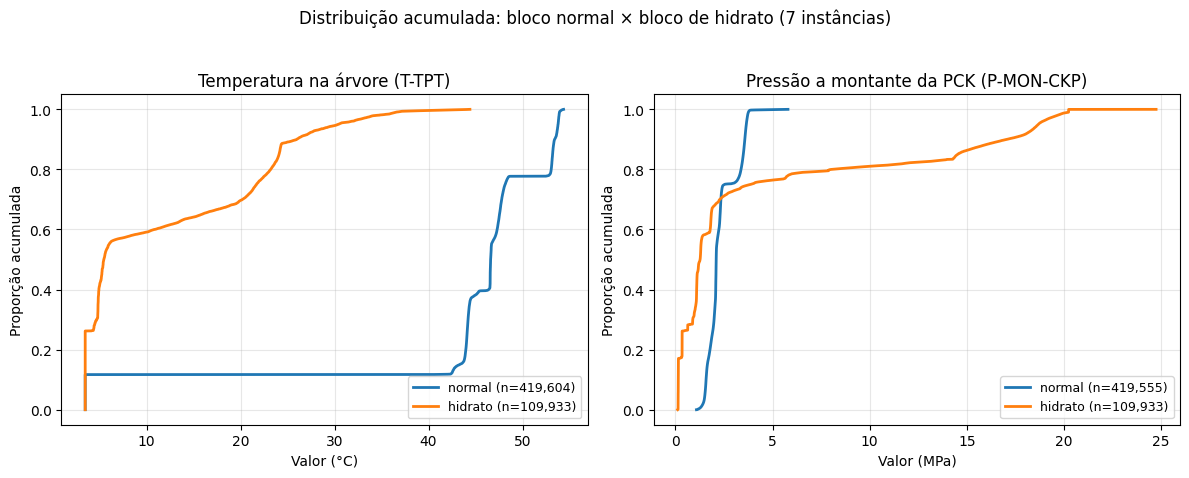

T-TPT: mediana normal = 46.60; mediana hidrato = 5.45; n = 419,604 / 109,933
P-MON-CKP: mediana normal = 2.10; mediana hidrato = 1.27; n = 419,555 / 109,933


In [11]:
import matplotlib.pyplot as plt


def instancias_com_temperatura_valida(instancias):
    selecionadas = {}
    for nome, df in instancias.items():
        s = df["T-TPT"].dropna()
        if len(s) and (s >= -10).mean() >= 0.99:
            selecionadas[nome] = df
    return selecionadas


def series_por_classe(instancias, coluna):
    normal, hidrato = [], []
    for df in instancias.values():
        s = df[coluna].replace(list(CODIGOS_FALHA), np.nan).mask(lambda x: x.abs() > 1e12)
        normal.append(s[df["class"] == 0].dropna().to_numpy())
        hidrato.append(s[df["class"] == 8].dropna().to_numpy())
    return np.concatenate(normal), np.concatenate(hidrato)


def curva_ecdf(x):
    x = np.sort(x)
    return x, np.arange(1, len(x) + 1) / len(x)


validas = instancias_com_temperatura_valida(instancias)
print(f"instâncias com T-TPT plausível: {len(validas)} de {len(instancias)}")
print(", ".join(nome.split("_")[0] + "_" + nome.split("_")[1][:8] for nome in validas))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, coluna, titulo, unidade in (
    (axes[0], "T-TPT", "Temperatura na árvore (T-TPT)", "°C"),
    (axes[1], "P-MON-CKP", "Pressão a montante da PCK (P-MON-CKP)", "MPa"),
):
    normal, hidrato = series_por_classe(validas, coluna)
    fator = 1e6 if coluna.startswith("P-") else 1.0
    xn, yn = curva_ecdf(normal / fator)
    xh, yh = curva_ecdf(hidrato / fator)
    ax.plot(xn, yn, lw=2, label=f"normal (n={len(normal):,})")
    ax.plot(xh, yh, lw=2, label=f"hidrato (n={len(hidrato):,})")
    ax.set(title=titulo, xlabel=f"Valor ({unidade})", ylabel="Proporção acumulada")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right", fontsize=9)
fig.suptitle("Distribuição acumulada: bloco normal × bloco de hidrato (7 instâncias)", y=1.03)
plt.tight_layout()
display(fig)
plt.close(fig)

for coluna in ("T-TPT", "P-MON-CKP"):
    n, h = series_por_classe(validas, coluna)
    fator = 1e6 if coluna.startswith("P-") else 1.0
    print(f"{coluna}: mediana normal = {np.median(n)/fator:,.2f}; "
          f"mediana hidrato = {np.median(h)/fator:,.2f}; "
          f"n = {len(n):,} / {len(h):,}")

A Figura 1 mostra uma diferença nítida entre o comportamento da temperatura e o da pressão. Nas 7 instâncias com sensor de temperatura em ordem, a temperatura na árvore cai de uma mediana de **46,60 °C** na operação normal (419.604 leituras) para **5,45 °C** no período com hidrato (109.933 leituras). As curvas de temperatura quase não se tocam: metade das leituras normais fica entre 44,1 °C e 48,2 °C, enquanto metade dos registros com hidrato fica entre 3,5 °C e 21,7 °C.

Já na pressão a montante da *choke* (`P-MON-CKP`), a mediana passa de 2,10 MPa no normal para 1,27 MPa no hidrato, mas as faixas se sobrepõem amplamente (1,89 a 2,53 MPa no normal versus 0,34 a 3,86 MPa com hidrato).

Esse resultado apoia a hipótese $H_1$: o resfriamento na árvore é um sinal bem mais claro e confiável do que a variação de pressão neste recorte. Dois cuidados, porém, são necessários: 5 poços não mediram essa temperatura e 2 registraram códigos de falha, de modo que o achado se aplica às 7 instâncias avaliadas. Além disso, no poço WELL-00027 o sensor marcou um valor constante de 3,47 °C, mostrando que a medição depende do estado do instrumento. Por fim, como se trata de uma base observacional, o resfriamento está associado ao evento, mas não podemos afirmar que foi a causa direta do hidrato.

### Figura 2 — Teste de $H_1$: A queda de temperatura se repete em cada poço individualmente?

**Pergunta:** A boa separação proporcionada pela temperatura acontece em todos os poços ou é puxada por apenas alguns casos? Para comparar variáveis com unidades diferentes (°C e Pa), calculamos a probabilidade de uma leitura do bloco normal ser maior que uma do bloco com hidrato (área sob a curva empírica, AUC). Um valor próximo de 0,5 indica que as leituras se misturam sem separação; perto de 1,0 indica resfriamento ou queda de pressão no hidrato; e perto de 0,0 indica aquecimento ou aumento de pressão.

**Escolha do gráfico:** Um gráfico de dispersão com um ponto para cada instância permite enxergar o comportamento poço a poço, sem esconder diferenças sob uma média geral.

,T-TPT,T-MON-CKP,P-TPT,P-MON-CKP
instância,,,,
WELL-00019_20120601,1.0,0.023,0.000,1.000
WELL-00019_20141117,1.0,0.509,0.000,0.949
WELL-00019_20150614,1.0,1.000,0.127,0.081
WELL-00019_20210617,NaN,1.000,0.503,1.000
WELL-00025_20200629,1.0,0.997,0.000,0.264
WELL-00026_20160601,NaN,1.000,NaN,0.530
WELL-00027_20230918,0.5,1.000,0.045,1.000
WELL-00028_20210617,NaN,1.000,0.207,1.000
WELL-00029_20201020,1.0,1.000,0.500,0.123


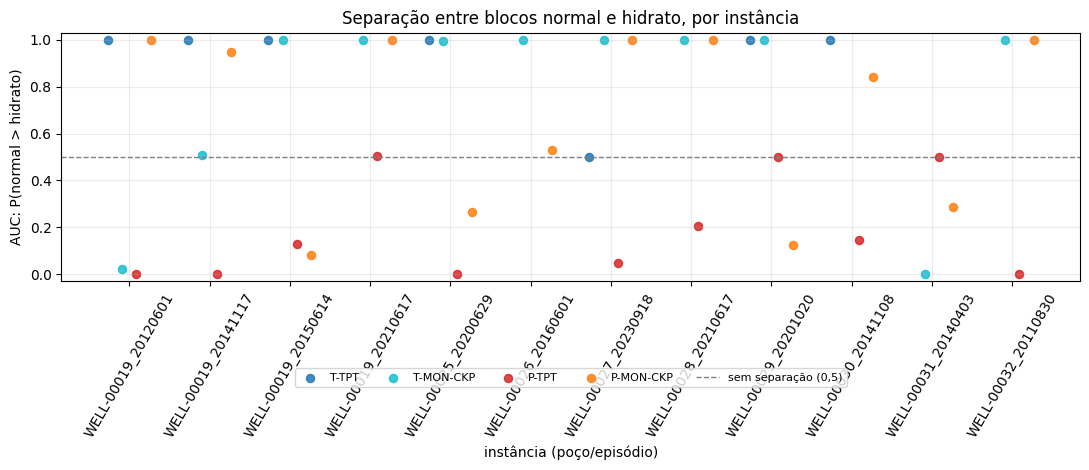

,median,count,n_com_AUC_>=_0.9
T-TPT,1.000,7.0,6
T-MON-CKP,1.000,11.0,8
P-TPT,0.127,11.0,0
P-MON-CKP,0.895,12.0,6


In [12]:
VARIAVEIS_AUC = ("T-TPT", "T-MON-CKP", "P-TPT", "P-MON-CKP")
CORES = {"T-TPT": "#1f77b4", "T-MON-CKP": "#17becf",
         "P-TPT": "#d62728", "P-MON-CKP": "#ff7f0e"}
rng = np.random.default_rng(SEMENTE)


def probabilidade_de_superioridade(normal, hidrato):
    a = np.asarray(normal, dtype=float)
    b = np.asarray(hidrato, dtype=float)
    a = a[np.isfinite(a)]
    b = b[np.isfinite(b)]
    if len(a) < 2 or len(b) < 2:
        return np.nan
    a = rng.choice(a, size=min(3000, len(a)), replace=False)
    b = rng.choice(b, size=min(3000, len(b)), replace=False)
    ranks = pd.Series(np.concatenate([a, b])).rank(method="average").to_numpy()
    u = ranks[:len(a)].sum() - len(a) * (len(a) + 1) / 2
    return u / (len(a) * len(b))


linhas = []
for nome, df in instancias.items():
    if not (df["class"] == 8).any():
        continue
    registro = {"instância": f"{nome_do_poco(nome)}_{nome.split('_')[1][:8]}"}
    for coluna in VARIAVEIS_AUC:
        s = df[coluna].replace(list(CODIGOS_FALHA), np.nan).mask(lambda x: x.abs() > 1e12)
        if coluna == "T-TPT":
            s = s.mask(s < -10)
        registro[coluna] = probabilidade_de_superioridade(
            s[df["class"] == 0].dropna(), s[df["class"] == 8].dropna())
    linhas.append(registro)
auc_por_instancia = pd.DataFrame(linhas)
display(auc_por_instancia.round(3).set_index("instância"))

fig, ax = plt.subplots(figsize=(11, 4.8))
posicoes = np.arange(len(auc_por_instancia))
for deslocamento, coluna in enumerate(VARIAVEIS_AUC):
    ax.scatter(posicoes + 0.18 * (deslocamento - 1.5), auc_por_instancia[coluna],
               s=34, alpha=0.85, color=CORES[coluna], label=coluna)
ax.axhline(0.5, color="grey", ls="--", lw=1, label="sem separação (0,5)")
ax.set(xticks=posicoes, xticklabels=auc_por_instancia["instância"], ylim=(-0.03, 1.03),
       xlabel="instância (poço/episódio)", ylabel="AUC: P(normal > hidrato)",
       title="Separação entre blocos normal e hidrato, por instância")
ax.tick_params(axis="x", labelrotation=60)
ax.grid(alpha=0.25)
ax.legend(ncol=5, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.45))
plt.tight_layout()
display(fig)
plt.close(fig)

resumo_auc = auc_por_instancia[list(VARIAVEIS_AUC)].agg(["median", "count"]).T
resumo_auc["n_com_AUC_>=_0.9"] = (auc_por_instancia[list(VARIAVEIS_AUC)] >= 0.9).sum()
display(resumo_auc.round(3))

O gráfico da Figura 2 confirma que a queda na temperatura da árvore (`T-TPT`) é consistente: a separação atinge índice $\ge 0,90$ em **6 das 7 instâncias** válidas (mediana de 1,000). A única exceção é o poço WELL-00027, cujo sensor ficou travado em 3,47 °C (índice 0,500).

Por outro lado, o sensor antes da *choke* (`T-MON-CKP`) não apresenta o mesmo padrão: embora 8 das 11 instâncias com leitura tenham índice $\ge 0,90$, **duas instâncias mostram comportamento inverso, com aquecimento durante o hidrato**: WELL-00019_20120601 (onde a mediana sobe de 14,11 °C para 26,95 °C) e WELL-00031_20140403 (subindo de 33,42 °C para 39,84 °C). Ou seja, a temperatura na *choke* não serve como sinal confiável de resfriamento.

Em relação à pressão, a medição a montante da *choke* oscila bastante entre poços (índice mediano de 0,895, variando de 0,081 a 1,000). Já a pressão na árvore (`P-TPT`) tem índice mediano de 0,127, ficando abaixo de 0,50 em 8 das 11 instâncias — o que mostra que a pressão na árvore tende a **subir** durante a obstrução, acumulando contrapressão antes do ponto de bloqueio, como descreve a literatura da área.

Esses números reforçam $H_1$, com a ressalva de que o resfriamento confiável ocorre especificamente na árvore submarina (`T-TPT`). Trata-se de uma análise descritiva das distribuições históricas, sem pretensão de medir o desempenho de um detector automático.

### Figura 3 — Teste de $H_2$: Em quais estados operacionais o hidrato aparece?

**Pergunta:** Das 140.920 leituras registradas com hidrato estacionário (`class = 8`), quantas acontecem enquanto o poço está produzindo normalmente (*Open*) e quantas ocorrem durante manobras operacionais?

**Escolha do gráfico:** Gráfico de barras horizontais ordenado por volume, em escala logarítmica. A escala logarítmica é necessária porque a quantidade de leituras em produção aberta é muito menor do que nas fases de reinício e circulação, permitindo comparar todas as categorias no mesmo painel com clareza.

,estado,linhas,% das linhas com hidrato
0,Open,5679,4.03
1,Bullheading,8832,6.27
2,Flushing Diesel,62318,44.22
3,Restart,64091,45.48


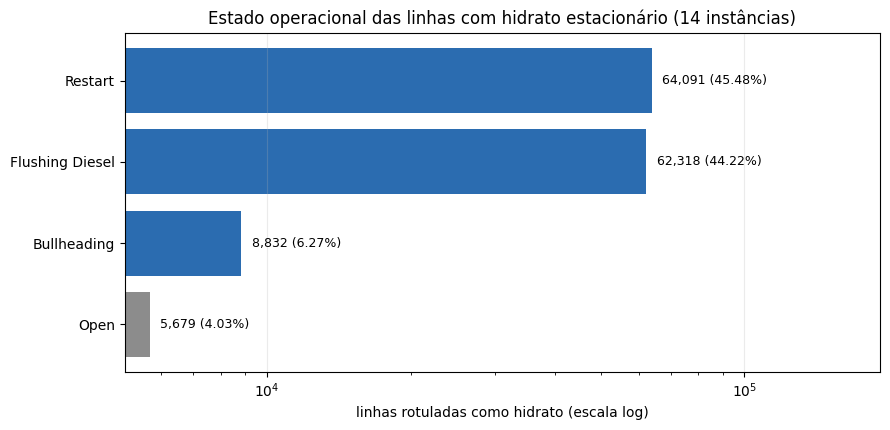

total com hidrato: 140,920 | fora de Open: 95.97%


In [13]:
rotuladas = pd.concat([df.loc[df["class"] == 8, ["state"]] for df in instancias.values()])
contagem = rotuladas["state"].value_counts().sort_values()
tabela_h2 = pd.DataFrame({
    "estado": [NOMES_STATE.get(int(k), str(k)) for k in contagem.index],
    "linhas": contagem.to_numpy(),
    "% das linhas com hidrato": (100 * contagem / len(rotuladas)).round(2).to_numpy(),
})
display(tabela_h2)

fig, ax = plt.subplots(figsize=(9, 4.4))
barras = ax.barh(tabela_h2["estado"], tabela_h2["linhas"],
                 color=["#8c8c8c" if e == "Open" else "#2b6cb0"
                        for e in tabela_h2["estado"]])
ax.set_xscale("log")
ax.set(xlabel="linhas rotuladas como hidrato (escala log)",
       title="Estado operacional das linhas com hidrato estacionário (14 instâncias)")
for barra, valor, pct in zip(barras, tabela_h2["linhas"], tabela_h2["% das linhas com hidrato"]):
    ax.text(valor * 1.05, barra.get_y() + barra.get_height() / 2,
            f"{valor:,} ({pct:.2f}%)", va="center", fontsize=9)
ax.set_xlim(right=tabela_h2["linhas"].max() * 3)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
display(fig)
plt.close(fig)

fora_open = 100 * (1 - contagem.get(0, 0) / len(rotuladas))
print(f"total com hidrato: {len(rotuladas):,} | fora de Open: {fora_open:.2f}%")

A contagem da Figura 3 mostra que, das 140.920 leituras com hidrato consolidado, **64.091 (45,48%)** ocorrem durante o reinício do poço (*Restart*), **62.318 (44,22%)** durante a lavagem da linha com diesel (*Flushing Diesel*), **8.832 (6,27%)** sob injeção forçada (*Bullheading*) e apenas **5.679 (4,03%)** durante a produção estável (*Open*). Isso significa que **95,97%** dos registros de hidrato acontecem durante intervenções e manobras da equipe, e quase nunca em operação contínua.

O resultado confirma a hipótese $H_2$. Na prática da operação submarina, lavagens com diesel e tentativas de reinício são manobras ativadas justamente quando os operadores desconfiam de restrição no fluxo. Portanto, essa concentração reflete o período em que a equipe estava intervindo para desobstruir o duto, demonstrando que o problema persiste e se torna crítico durante essas manobras.

### Figura 4 — Teste de $H_2$: Qual é a ordem dos acontecimentos ao longo de um episódio?

**Pergunta:** Em um caso concreto de campo, qual é a ordem cronológica dos estados operacionais que antecedem e acompanham o hidrato?

**Escolha do gráfico:** Uma linha do tempo ilustrando as fases operacionais. Para manter o gráfico leve e legível sem desenhar 243.137 pontos, pegamos uma leitura por minuto. Como as transições de estado demoram horas, essa amostragem preserva a sequência completa dos acontecimentos.

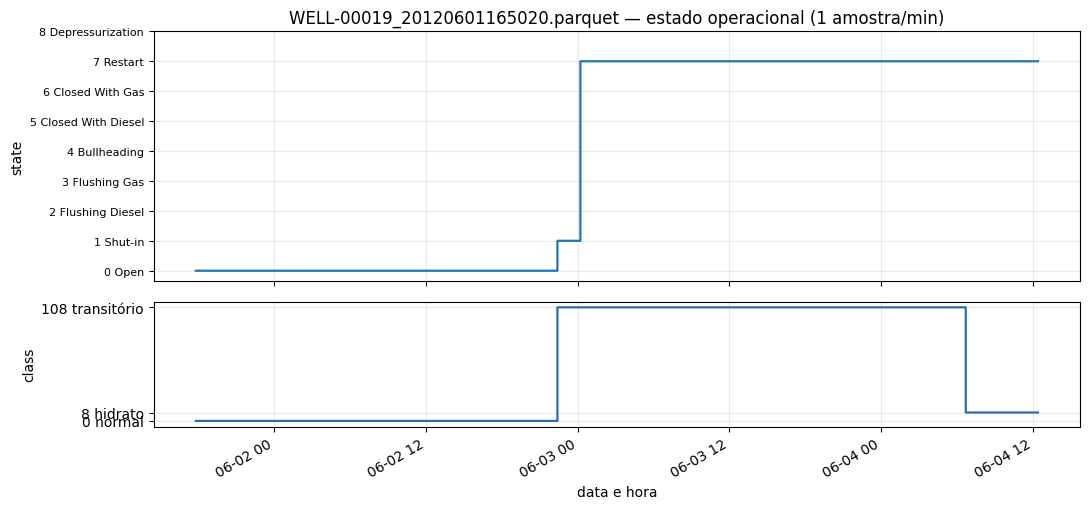

 rotulo              inicio                 fim  linhas
   -1.0 2012-06-01 16:50:20 2012-06-01 17:50:19    3600
    0.0 2012-06-01 17:50:20 2012-06-02 22:23:30  102791
  108.0 2012-06-02 22:23:31 2012-06-04 06:39:58  116188
    8.0 2012-06-04 06:39:59 2012-06-04 12:22:36   20558

classe × state nesta instância:


state,0,1,7
class,,,
0,102791,0,0
8,0,0,20558
108,0,6581,109607


In [14]:
nome_exemplo = "WELL-00019_20120601165020.parquet"
exemplo = instancias[nome_exemplo]
amostra = exemplo.iloc[::60]

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})
ax0.step(amostra.index, amostra["state"].astype("Float64").ffill(), where="post", lw=1.6)
ax0.set(ylabel="state", title=f"{nome_exemplo} — estado operacional (1 amostra/min)")
ax0.set_yticks(list(NOMES_STATE))
ax0.set_yticklabels([f"{k} {v}" for k, v in NOMES_STATE.items()], fontsize=8)
ax0.grid(alpha=0.25)
ax1.step(amostra.index, amostra["class"].astype("Float64").ffill(), where="post",
         lw=1.6, color="#2b6cb0")
ax1.set(ylabel="class", xlabel="data e hora", yticks=[0, 108, 8],
        yticklabels=["0 normal", "108 transitório", "8 hidrato"])
ax1.grid(alpha=0.25)
fig.autofmt_xdate()
plt.tight_layout()
display(fig)
plt.close(fig)

blocos_exemplo = blocos_de_rotulo(exemplo)
print(blocos_exemplo.to_string(index=False))
print("\nclasse × state nesta instância:")
display(pd.crosstab(exemplo["class"], exemplo["state"]))

No episódio de 01 a 04/06/2012 do poço WELL-00019, a linha do tempo revela uma sequência clara: o poço operou em produção normal (*Open*) por cerca de 28 horas (até as 22h23 de 02/06), foi fechado (*Shut-in*) por 1h49 e, a partir da meia-noite de 03/06, entrou em procedimento de reinício (*Restart*), onde permaneceu por mais de 36 horas.

Todas as **20.558 leituras com hidrato estacionário** desse episódio ocorreram dentro do período de reinício (*Restart*). O período de transição preliminar começou ainda durante o fechamento do poço (6.581 leituras) e se estendeu pelo reinício, até a confirmação do bloqueio.

Essa visão cronológica detalha o que vimos na Figura 3: o hidrato se desenvolve e se consolida após o fechamento do poço, aparecendo na tentativa de retomada de fluxo. Embora seja o registro de um único poço, esse caso ilustra a dinâmica física comum em linhas submarinas, onde o óleo e o gás estagnados no duto resfriam rapidamente sob a água fria do leito marinho, propiciando a formação dos cristais.

# 5. Pré-processamento e decisões de tratamento

## 5.1 Planejamento das decisões e cuidados com vazamento de dados

O diagnóstico exploratório apontou três necessidades de tratamento: (i) cinco colunas que nunca registraram nenhuma medição; (ii) 24.775 leituras consecutivas com valores idênticos causadas pela resolução do sensor a cada segundo; e (iii) códigos de erro de sensor desligado registrados como números válidos. Essas três frentes são tratadas nas decisões D1, D2 e D3 a seguir.

**Por que não há divisão entre treino e teste:**
Como este trabalho tem objetivo puramente descritivo e não treina modelos preditivos, não faz sentido dividir a base em treino e teste. Dividir os dados por linhas quebraria a continuidade temporal das medições, e dividir por poços deixaria amostras pequenas demais (são apenas 9 poços). Como nenhum algoritmo está ajustando parâmetros (como médias, escalas ou frequências) em uma parte dos dados para aplicar em outra, o risco de vazamento de dados (*data leakage*) não se aplica a este estudo. Essa justificativa está devidamente registrada no item 9 do checklist final.

**Rastreabilidade:**
Os dados brutos originais são mantidos intactos na variável `instancias`. As transformações são aplicadas exclusivamente em um dicionário de cópias (`preparadas`), permitindo auditar o antes e o depois de cada intervenção a qualquer momento.

In [15]:
preparadas = {nome: df.copy(deep=True) for nome, df in instancias.items()}
linhas_totais = sum(len(df) for df in preparadas.values())
colunas_totais = preparadas[next(iter(preparadas))].shape[1]

print(f"visão de origem: {len(instancias)} instâncias | {linhas_totais:,} linhas | "
      f"{colunas_totais} colunas (inalterada)")
print(f"visão preparada: {len(preparadas)} instâncias | "
      f"{sum(len(df) for df in preparadas.values()):,} linhas | "
      f"{preparadas[next(iter(preparadas))].shape[1]} colunas (cópia de trabalho)")
print(f"poços independentes: {len({nome_do_poco(n) for n in preparadas})}")
print("divisão treino/teste: não aplicável — objetivo descritivo, nenhum parâmetro é ajustado")

visão de origem: 14 instâncias | 4,809,035 linhas | 29 colunas (inalterada)
visão preparada: 14 instâncias | 4,809,035 linhas | 29 colunas (cópia de trabalho)
poços independentes: 9
divisão treino/teste: não aplicável — objetivo descritivo, nenhum parâmetro é ajustado


## 5.2 Decisão D1 — Exclusão das colunas sem nenhuma medição

**Problema e evidência:** O diagnóstico de ausências (§4.1) mostrou que cinco colunas estão 100% vazias em todas as 14 instâncias: `P-JUS-BS`, `QBS`, `T-JUS-CKP`, `P-MON-SDV-P` e `PT-P` (4.809.035 valores ausentes em cada uma). Esses sensores simplesmente não foram instalados nesses poços.

**Alternativas consideradas:**
- *Alternativa A:* Manter as colunas e preencher os valores com uma constante arbitrária (como zero ou uma média estimada);
- *Alternativa B:* Remover as cinco colunas da base preparada, documentando os motivos da exclusão;
- *Alternativa C:* Manter as colunas inteiramente preenchidas com `NaN`.

**Opção escolhida e justificativa:** Adotamos a **Alternativa B**. Preencher colunas que nunca mediram nada exigiria inventar mais de 24 milhões de números artificiais, criando variáveis com variância zero que não agregam informação real. Remover essas colunas limpa a estrutura de dados sem descartar nenhuma observação real. A tabela original continua preservada com todas as colunas.

In [16]:
COLUNAS_VAZIAS = list(ausencias[ausencias["ausentes"] == linhas_totais].index)
print("colunas removidas:", COLUNAS_VAZIAS)

exemplo = instancias[next(iter(instancias))][COLUNAS_VAZIAS]
imputada = exemplo.fillna(0.0)
comparacao_d1 = pd.DataFrame([
    {
        "alternativa": "A: manter e preencher com 0",
        "colunas": len(exemplo.columns),
        "células_inventadas_na_instância": int(exemplo.isna().to_numpy().sum()),
        "desvio-padrão_resultante": float(imputada.std().iloc[0]),
        "valores_distintos_resultantes": int(imputada.nunique().iloc[0]),
    },
    {
        "alternativa": "B: remover colunas",
        "colunas": 0,
        "células_inventadas_na_instância": 0,
        "desvio-padrão_resultante": np.nan,
        "valores_distintos_resultantes": 0,
    },
])
display(comparacao_d1)
print(f"células inventadas no total se A fosse adotada: "
      f"{len(COLUNAS_VAZIAS) * linhas_totais:,}")

preparadas = {nome: df.drop(columns=COLUNAS_VAZIAS) for nome, df in preparadas.items()}
print("dimensão após D1:", preparadas[next(iter(preparadas))].shape)

colunas removidas: ['P-JUS-BS', 'QBS', 'T-JUS-CKP', 'P-MON-SDV-P', 'PT-P']


,alternativa,colunas,células_inventadas_na_instância,desvio-padrão_resultante,valores_distintos_resultantes
0,A: manter e preencher com 0,5,1215685,0.0,1
1,B: remover colunas,0,0,NaN,0


células inventadas no total se A fosse adotada: 24,045,175


dimensão após D1: (243137, 24)


A comparação prática entre as alternativas mostra o impacto direto da decisão: a opção por preencher (Alternativa A) criaria 1.215.685 números sintéticos por coluna em um único poço e mais de 24 milhões no total, sem qualquer fundamento físico. A exclusão (Alternativa B) reduz a base de 29 para **24 colunas**, mantendo intactas todas as 4.809.035 linhas originais. As variáveis removidas ficam registradas no relatório, e a base original (`instancias`) continua com suas 29 colunas para auditoria.

A limitação dessa decisão é a perda de variáveis que seriam úteis para a análise — em especial `T-JUS-CKP` (temperatura após a *choke*) e `QBS` (vazão de injeção). Sem elas, nossa análise térmica fica restrita aos sensores `T-TPT` e `T-MON-CKP`. A remoção evita dados inventados, mas não recupera a falta do sensor no poço.

## 5.3 Decisão D2 — Manutenção de leituras consecutivas idênticas para preservar a grade temporal

**Problema e evidência:** A verificação de integridade (§4.1) identificou 24.775 linhas contíguas com valores repetidos (0,52% dos dados), principalmente nas instâncias WELL-00019 (15.333) e WELL-00028 (4.616). Esses registros possuem horários distintos e consecutivos, dentro de uma grade regular de 1 segundo.

**Alternativas consideradas:**
- *Alternativa A:* Eliminar as linhas repetidas com o comando `drop_duplicates()`;
- *Alternativa B:* Manter as linhas, entendendo que leituras idênticas em segundos seguidos decorrem da resolução finita do sensor quando a variável física está estável.

**Opção escolhida e justificativa:** Adotamos a **Alternativa B (manter os dados como estão)**. Apagar linhas com registro de horário válido criaria buracos na série temporal, gerando saltos de 2 segundos ou mais em vez do passo uniforme de 1 segundo. Para séries temporais, manter a regularidade da grade de tempo é mais importante do que forçar valores diferentes a cada segundo. A repetição não é erro de digitação nem duplicação de banco de dados; é o comportamento normal de um instrumento digital quando o processo físico não varia além do seu limiar de detecção.

In [17]:
quebras_apos_exclusao = 0
for df in preparadas.values():
    # Mede o efeito real da alternativa A: remover duplicatas e conferir a grade resultante.
    sem_duplicatas = df[~df.duplicated(keep="first")]
    passos = np.diff(sem_duplicatas.index.to_numpy().astype("datetime64[s]").astype("int64"))
    quebras_apos_exclusao += int((passos != 1).sum())

duplicadas_totais = sum(int(df.duplicated().sum()) for df in preparadas.values())
comparacao_d2 = pd.DataFrame([
    {"alternativa": "A: excluir duplicatas", "linhas": linhas_totais - duplicadas_totais,
     "intervalos_fora_de_1s": quebras_apos_exclusao, "linhas_removidas": duplicadas_totais},
    {"alternativa": "B: manter duplicatas", "linhas": linhas_totais,
     "intervalos_fora_de_1s": 0, "linhas_removidas": 0},
])
display(comparacao_d2)
print(f"duplicadas: {duplicadas_totais:,} ({100*duplicadas_totais/linhas_totais:.2f}% das linhas)")
print("opção adotada: B — nenhuma linha removida")

,alternativa,linhas,intervalos_fora_de_1s,linhas_removidas
0,A: excluir duplicatas,4784260,6757,24775
1,B: manter duplicatas,4809035,0,0


duplicadas: 24,775 (0.52% das linhas)
opção adotada: B — nenhuma linha removida


A comparação numérica entre as alternativas deixa o efeito evidente: aplicar a exclusão (Alternativa A) descartaria 24.775 linhas e deixaria **6.757 intervalos sem medição** na linha do tempo. Já a manutenção (Alternativa B) conserva todas as 4.809.035 linhas e mantém o intervalo regular de 1 segundo em 100% dos registros. A integridade temporal foi verificada após a decisão e permanece impecável.

A limitação a considerar é que patamares fixos muito longos podem alterar cálculos estatísticos de frequência caso o sistema de gravação use compressão por repetição. Como nosso objetivo é a preservação da série temporal uniforme, manter as linhas foi a escolha mais segura.

## 5.4 Decisão D3 — Conversão de códigos de erro de sensor em dados ausentes, sem imputação

**Problema e evidência:** O diagnóstico exploratório (§4.1) revelou números absurdos que representam códigos de falha de instrumento: `T-PDG` marcando $-1,41 \times 10^{20}$ °C, `P-TPT` marcando $-8.629.852$ Pa, e o poço WELL-00030 inteiro registrando $-99,99$ em `T-MON-CKP` e `ABER-CKP` e $-9.999.000$ em `P-JUS-CKP`. Além disso, duas instâncias registram temperatura na árvore em torno de $-25$ °C. Trata-se de convenções dos sistemas de supervisão para indicar que o canal está inoperante.

**Alternativas consideradas:**
- *Alternativa A:* Manter os códigos como números válidos;
- *Alternativa B:* Trocar os códigos por `NaN` e preencher os buracos por interpolação ou mediana;
- *Alternativa C:* Trocar os códigos por `NaN`, deixando-os como dados ausentes, sem inventar valores.

**Opção escolhida e justificativa:** Adotamos a **Alternativa C**. Manter os códigos (Alternativa A) distorce completamente as médias e desvios (a média de `T-PDG` ficava na casa de $10^{19}$). Preencher por estimativa (Alternativa B) inventaria dias inteiros de medição em poços onde o sensor não estava funcionando. Converter para `NaN` sem imputar reflete honestamente a indisponibilidade do sensor e não falsifica dados físicos.

A regra de conversão é transparente e objetiva: substituímos os códigos `-99,99`, `-9.999.000` e `-25,0`, valores com módulo maior que $10^{12}$ e leituras abaixo de $-10$ °C nos sensores `T-TPT` e `T-PDG`.

In [18]:
# Reutiliza `CODIGOS_FALHA`, definido na seção 4.2 (estatísticas descritivas).


def mapa_de_falhas(df):
    falha = pd.DataFrame(False, index=df.index, columns=df.columns)
    for coluna in df.select_dtypes(include="number").columns:
        s = df[coluna]
        mascara = s.isin(CODIGOS_FALHA) | s.abs().gt(1e12)
        if coluna in ("T-TPT", "T-PDG"):
            mascara = mascara | s.lt(-10)
        falha[coluna] = mascara.fillna(False)
    return falha


mapas = {nome: mapa_de_falhas(df) for nome, df in preparadas.items()}
contagem_falhas = pd.Series({
    coluna: sum(int(mapa[coluna].sum()) for mapa in mapas.values())
    for coluna in preparadas[next(iter(preparadas))].columns
}).sort_values(ascending=False)
display(contagem_falhas[contagem_falhas > 0].rename("células convertidas em ausência").to_frame())


def estatistica_da_coluna(coluna, aplicar_mascara):
    partes = []
    for nome, df in preparadas.items():
        s = df[coluna]
        if aplicar_mascara:
            s = s.mask(mapas[nome][coluna])
        partes.append(s.dropna().to_numpy())
    valores = np.concatenate(partes)
    return {"n": len(valores), "mínimo": valores.min(), "máximo": valores.max(),
            "média": valores.mean(), "desvio-padrão": valores.std()}


comparacao_d3 = pd.DataFrame([
    {"variável": coluna, "momento": momento, **estatistica_da_coluna(coluna, momento == "depois")}
    for coluna in ("T-PDG", "T-TPT") for momento in ("antes", "depois")
])
display(comparacao_d3.round(3).set_index(["variável", "momento"]))

preparadas = {nome: df.mask(mapas[nome]) for nome, df in preparadas.items()}
print("regra aplicada; visão de origem preservada em `instancias`")

,células convertidas em ausência
T-PDG,566324
T-TPT,388925
ABER-CKP,161538
P-JUS-CKP,161538
T-MON-CKP,161538


n        mínimo   máximo         média  desvio-padrão
variável momento                                                             
T-PDG    antes    3764451 -1.413714e+20  177.801 -1.170203e+19   3.895328e+19
         depois   3198127  0.000000e+00  177.801  8.310700e+01   2.660800e+01
T-TPT    antes    2824367 -2.500000e+01   55.011  7.970000e+00   2.085700e+01
         depois   2435442 -1.010000e+00   55.011  1.322800e+01   1.742600e+01

regra aplicada; visão de origem preservada em `instancias`


A regra converteu **1.439.863 valores** em ausência, concentrados em `T-PDG` (566.324), `T-TPT` (388.925) e nas variáveis do poço WELL-00030 (161.538 cada). A checagem antes e depois demonstra a correção: a média de `T-PDG`, que era de $-1,17 \times 10^{19}$ °C com desvio-padrão de $3,90 \times 10^{19}$ °C, passou para 83,1 °C com desvio de 26,6 °C — valores condizentes com o fundo de um poço de petróleo. Em `T-TPT`, o menor valor registrado subiu de $-25,0$ °C para $-1,01$ °C. A base original não foi modificada.

A limitação dessa intervenção é a perda de volume de dados nessas variáveis: nos poços WELL-00030 e WELL-00032, os sensores de temperatura afetados ficaram totalmente sem leitura, restringindo nossa comparação em $H_1$ às 7 instâncias com medições válidas. O limite de $-10$ °C é baseado na física do leito oceânico tropical; embora não tenhamos observado transientes reais abaixo desse patamar, é uma regra empírica de bom senso.

## 5.5 Estado consolidado dos dados e verificações finais

O fluxo de tratamento organiza os dados em três visões bem definidas:
1. `instancias`: dados **originais intactos** (14 arquivos, 4.809.035 linhas e 29 colunas);
2. `preparadas`: dados **tratados** (mesmas linhas, 24 colunas úteis e códigos de erro convertidos em `NaN`, sem inventar valores);
3. `validas`: recorte com as **7 instâncias com temperatura válida**, usado especificamente nas figuras de $H_1$.

Nenhuma linha foi apagada, os nomes dos poços foram mantidos e a ordem dos rótulos permaneceu a mesma. A rotina abaixo valida dimensões, ausências, duplicidades e contagens de classe antes e depois do tratamento, e salva uma tabela compacta de conferência em `data/resumo_por_instancia_classe.csv`. Todo o processo pode ser reexecutado do início ao fim a partir do código do notebook.

In [19]:
verificacao = pd.DataFrame([
    {"visão": "origem (`instancias`)", "instâncias": len(instancias),
     "linhas": sum(len(d) for d in instancias.values()),
     "colunas": instancias[next(iter(instancias))].shape[1]},
    {"visão": "preparada (`preparadas`)", "instâncias": len(preparadas),
     "linhas": sum(len(d) for d in preparadas.values()),
     "colunas": preparadas[next(iter(preparadas))].shape[1]},
])
display(verificacao)

ausencias_finais = pd.concat([d.isna().sum() for d in preparadas.values()], axis=1).sum(axis=1)
print(f"colunas sem ausência: {(ausencias_finais == 0).sum()} de {len(ausencias_finais)}")
duplicadas_origem = sum(int(d.duplicated().sum()) for d in instancias.values())
duplicadas_finais = sum(int(d.duplicated().sum()) for d in preparadas.values())
print(f"linhas duplicadas: {duplicadas_origem:,} na origem e {duplicadas_finais:,} após D3")
print("nenhuma linha foi excluída; o aumento ocorre porque linhas que diferiam apenas em "
      "códigos de falha passaram a ser idênticas após a conversão em NaN")
print(f"passos fora de 1s (inalterado): "
      f"{sum(int((d.index.to_series().diff().dropna() != pd.Timedelta('1s')).sum()) for d in preparadas.values())}")

rotulos_origem = pd.concat([d["class"] for d in instancias.values()], ignore_index=True)
rotulos_finais = pd.concat([d["class"] for d in preparadas.values()], ignore_index=True)
print("rótulos idênticos após o pré-processamento:", rotulos_origem.equals(rotulos_finais))
display(pd.concat([rotulos_finais.value_counts(dropna=False).sort_index().rename("linhas"),
                   (100 * rotulos_finais.value_counts(dropna=False, normalize=True)
                    .sort_index()).round(2).rename("%")], axis=1))

def mediana_se_houver(serie, casas=3):
    return round(float(serie.dropna().median()), casas) if serie.notna().any() else np.nan


resumo_linhas = []
for nome, df in preparadas.items():
    for rotulo, parte in df.groupby("class", dropna=False):
        resumo_linhas.append({
            "instância": nome, "poco": nome_do_poco(nome),
            "class": "ausente" if pd.isna(rotulo) else int(rotulo),
            "linhas": len(parte),
            "ausentes_pct": round(100 * float(parte.isna().to_numpy().mean()), 2),
            "T_TPT_mediana": mediana_se_houver(parte["T-TPT"]),
            "P_MON_CKP_mediana": mediana_se_houver(parte["P-MON-CKP"], 1),
        })
resumo_final = pd.DataFrame(resumo_linhas)
CAMINHO_RESUMO = Path("data") / "resumo_por_instancia_classe.csv"
resumo_final.to_csv(CAMINHO_RESUMO, index=False)
print(f"resumo exportado: {CAMINHO_RESUMO} ({len(resumo_final)} linhas)")
display(resumo_final.head(8))

,visão,instâncias,linhas,colunas
0,origem (`instancias`),14,4809035,29
1,preparada (`preparadas`),14,4809035,24


colunas sem ausência: 0 de 24


linhas duplicadas: 24,775 na origem e 25,084 após D3
nenhuma linha foi excluída; o aumento ocorre porque linhas que diferiam apenas em códigos de falha passaram a ser idênticas após a conversão em NaN


passos fora de 1s (inalterado): 0
rótulos idênticos após o pré-processamento: True


,linhas,%
class,,
0,962297,20.01
8,140920,2.93
108,3655418,76.01
<NA>,50400,1.05


resumo exportado: data\resumo_por_instancia_classe.csv (54 linhas)


,instância,poco,class,linhas,ausentes_pct,T_TPT_mediana,P_MON_CKP_mediana
0,WELL-00019_20120601165020.parquet,WELL-00019,0,102791,16.67,47.572,3535202.0
1,WELL-00019_20120601165020.parquet,WELL-00019,8,20558,16.67,4.959,1200397.0
2,WELL-00019_20120601165020.parquet,WELL-00019,108,116188,16.67,32.598,4411080.5
3,WELL-00019_20120601165020.parquet,WELL-00019,ausente,3600,25.00,47.120,3554187.0
4,WELL-00019_20141117190526.parquet,WELL-00019,0,40934,16.67,53.788,1567273.0
5,WELL-00019_20141117190526.parquet,WELL-00019,8,8236,16.67,5.406,972180.5
6,WELL-00019_20141117190526.parquet,WELL-00019,108,261834,16.67,4.799,870052.4
7,WELL-00019_20141117190526.parquet,WELL-00019,ausente,3600,25.00,53.718,1569630.0


# 6. Respostas às perguntas e conclusões

Retomamos as duas hipóteses investigadas, sintetizando as respostas encontradas, as evidências dos dados e o que permanece incerto:

| Hipótese | Resposta baseada nos dados | Evidência no notebook | Limitações observadas |
|---|---|---|---|
| **$H_1$** — Temperatura vs. Pressão | **Confirmada** para o sensor da árvore (`T-TPT`). O resfriamento é nítido e consistente; a pressão varia de forma instável e tende a subir no hidrato. | A mediana de `T-TPT` cai de 46,60 °C no normal para 5,45 °C no hidrato, com separação (AUC) $\ge 0,90$ em 6 de 7 poços válidos. Em `P-TPT`, a pressão sobe no hidrato (AUC mediano de 0,127) e em `P-MON-CKP` a resposta varia muito entre poços (0,081 a 1,000). (Figuras 1 e 2; §4.3). | 5 poços não medem `T-TPT`, 2 têm dados com falha e o poço WELL-00027 ficou travado. O sensor da *choke* (`T-MON-CKP`) registrou aquecimento em dois poços. A análise mostra associação, não causa direta. |
| **$H_2$** — Manobras vs. Produção Normal | **Confirmada**. O hidrato rotulado ocorre quase exclusivamente durante manobras de intervenção da equipe, e não em produção contínua. | 95,97% das 140.920 leituras com hidrato ocorrem fora de produção aberta: 45,48% em reinício (*Restart*), 44,22% em lavagem com diesel (*Flushing*) e 6,27% em injeção (*Bullheading*), contra apenas 4,03% em produção contínua (*Open*). Na WELL-00019, 100% do hidrato ocorre durante o reinício. (Figuras 3 e 4; §4.3). | As manobras são a resposta da operação ao problema percebido; os dados mostram que o hidrato persiste durante a intervenção, e não que a manobra tenha criado o hidrato. |
| **$H_3$** — Perda de carga (avaliação extra) | **Não foi possível testar** por falta de dados de vazão de produção na base. | A base mede apenas injeção de gás (`QGL`) e bombeio de serviço (`QBS`), sem medição de vazão de óleo/gás produzido. (Dicionário, §2.2; §1.2). | Sem vazão, a física dos fluidos não permite distinguir se a queda de pressão foi causada por entupimento ou por simples redução na produção do poço. |

**Conclusão geral:**
Os dados respondem de forma consistente às duas perguntas centrais: a presença de hidrato na linha submarina se manifesta fisicamente por um **resfriamento acentuado na árvore de natal submarina (`T-TPT`)** e está fortemente concentrada nos **períodos de manobra operacional (paradas, purgas e reinícios de poço)**. Essa dinâmica é explicada pela física do processo: quando o poço é fechado, o fluxo de óleo quente que vem do reservatório é interrompido, e o fluido parado na tubulação esfria em contato com a água fria do fundo do mar. Ao tentar reabrir o poço (*Restart*), a obstrução formada se manifesta plenamente.

**O que continua incerto:**
1. A utilidade prática da temperatura depende de o sensor `T-TPT` estar funcionando (quase metade dos poços não tinha essa leitura);
2. A temperatura na *choke* de superfície pode enganar, já que aqueceu em dois poços durante o hidrato;
3. O comportamento da pressão varia bastante de um poço para outro;
4. Os rótulos foram colocados por especialistas analisando esses mesmos sensores, o que significa que estamos avaliando a assinatura observada por eles, e não um teste cego independente.

**Próximos passos recomendados:**
Revisar a calibração dos sensores de temperatura nos poços problemáticos; repetir a análise no Evento 9 da base 3W (hidrato em linha de injeção de gás) para testar se a assinatura térmica se mantém; obter dados com medição de vazão de produção para avaliar a perda de carga; e, futuramente, testar modelos preditivos com divisão estrita de tempo por poço.

# 7. Checklist de conformidade com os requisitos do MVP

| Item avaliado | Onde encontrar no notebook | Justificativa de não aplicabilidade / observações |
|---|---|---|
| 1. Problema, unidade de observação, hipóteses e objetivo | §1.1 e §1.2 | Atendido integralmente. |
| 2. Fonte, período, recortes e dicionário de variáveis | §2.1, §2.2 e §3.2 | Atendido integralmente. |
| 3. Dimensões, tipos e estatísticas descritivas | §4.1 e §4.2 | Frequências relativas utilizadas para variáveis categóricas e de estado. |
| 4. Ausências, duplicidades, inconsistências e extremos | §4.1 e §5.4 | Valores absurdos classificados como códigos de falha de telemetria. |
| 5. Distribuições, relações e classes | §4.3 (Figuras 1 a 4) | Objetivo descritivo sem alvo preditivo; distribuição da classe na Seção 4.2. |
| 6. Interpretações após cada figura com evidências e limites | §4.3 (após cada figura) | Todas as figuras contam com achados numéricos e limitações explícitas. |
| 7. Decisões D1 a D3 e comparação de alternativas | §5.2 a §5.4 | D1 e D2 comparam duas alternativas com números; D3 compara antes e depois. |
| 8. Transformações e verificações antes/depois | §5.2 a §5.5 | D2 é manutenção justificada, garantindo a regularidade da grade de tempo. |
| 9. Divisão dos dados e prevenção de vazamento | §5.1 | **Não aplicável**: objetivo descritivo, sem treino de modelos ou ajuste de estimadores. |
| 10. Respostas às perguntas, limitações e próximos passos | §6 | Resumo em tabela comparativa e discussão objetiva dos limites. |
| 11. Referências e declaração de uso de IA | §8 | Referências formatadas e declaração de autoria e transparência. |
| 12. Execução, dados remotos e link do Colab | §3, Cabeçalho e README | Download automatizado via HTTPS sem credenciais; código testado e reprodutível. |

# 8. Referências e declaração de uso de IA

**Referências**

1. VARGAS, R. E. V. et al. *A realistic and public dataset with rare undesirable real events in oil wells*. Journal of Petroleum Science and Engineering, v. 180, p. 13–26, 2019. DOI: 10.1016/j.petrol.2019.106223.
2. PETROBRAS / CENPES; UFRJ. *3W Dataset, Versão 2.0.0*. Repositório GitHub, 2024. Disponível em: <https://github.com/petrobras/3W>. Acesso em: 25 nov. 2026.
3. VAZ VARGAS, R. E. et al. *3W Dataset 2.0.0: a realistic and public dataset with rare undesirable real events in oil wells*. Scientific Data, v. 13, art. 949, 2026. DOI: 10.1038/s41597-026-07225-z.
4. PUC-Rio / GRUPO A. *Sprint: Análise de Dados e Boas Práticas — Template do MVP*. 2026. Disponível em: <https://colab.research.google.com/drive/183mCH-PPPs8MLtcgq2Z1CeHzEJNyMXgJ>.
5. Documentação oficial das bibliotecas utilizadas: pandas, NumPy, Matplotlib e seaborn (versões indicadas na Seção 3.1 e em `requirements.txt`).

**Declaração de uso de IA**

Ferramentas de inteligência artificial foram empregadas unicamente como apoio operacional para digitação e estruturação de rotinas em Python, conferência de sintaxe e organização de tabelas. A definição das hipóteses, a fundamentação de engenharia, a interpretação crítica das saídas numéricas, as justificativas das decisões de tratamento e as conclusões finais foram desenvolvidas, revisadas e validadas pelo autor, que assume total responsabilidade pelo trabalho entregue.